Ξεκινάει η εκπαίδευση...
Epoch 10/100 | Train Loss: 0.0801 | Test Loss: 0.0606
Epoch 20/100 | Train Loss: 0.0525 | Test Loss: 0.0374
Epoch 30/100 | Train Loss: 0.0409 | Test Loss: 0.0283
Epoch 40/100 | Train Loss: 0.0341 | Test Loss: 0.0232
Epoch 50/100 | Train Loss: 0.0295 | Test Loss: 0.0199
Epoch 60/100 | Train Loss: 0.0262 | Test Loss: 0.0175
Epoch 70/100 | Train Loss: 0.0236 | Test Loss: 0.0157
Epoch 80/100 | Train Loss: 0.0216 | Test Loss: 0.0144
Epoch 90/100 | Train Loss: 0.0199 | Test Loss: 0.0133
Epoch 100/100 | Train Loss: 0.0185 | Test Loss: 0.0124

=== Τελικά Αποτελέσματα Logistic Regression ===
Accuracy (Train): 100.00%
Accuracy (Test):  100.00%


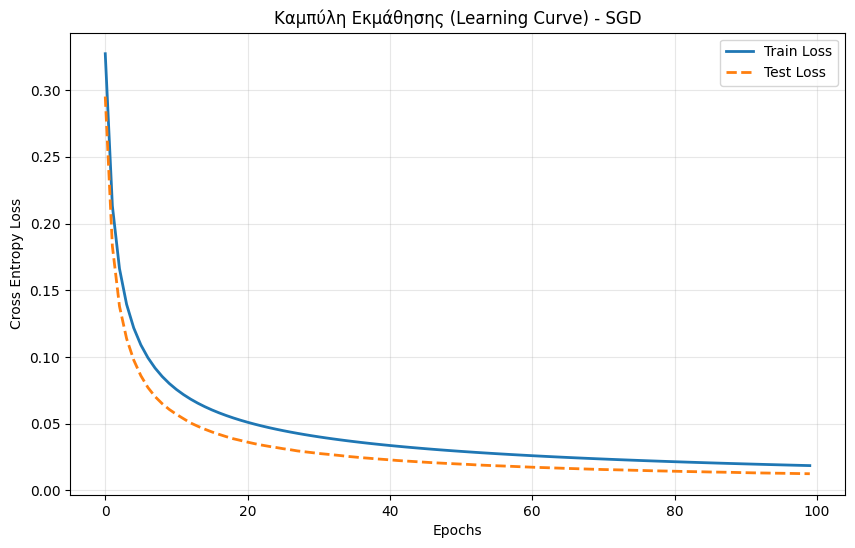

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# =========================================================
# ΒΗΜΑ 3: Logistic Regression με SGD (From Scratch)
# =========================================================

# 1. Βοηθητικές Συναρτήσεις (Helper Functions)

def softmax(z):
    """
    Υπολογίζει την πιθανότητα για κάθε κλάση.
    """
    # Αφαιρούμε το max για αριθμητική ευστάθεια (αποφυγή overflow)
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def cross_entropy_loss(y_true_one_hot, y_pred_probs):
    """
    Υπολογίζει το Cross Entropy Loss.
    """
    epsilon = 1e-9 # Μικρή σταθερά για να αποφύγουμε log(0)
    y_pred_probs = np.clip(y_pred_probs, epsilon, 1. - epsilon)
    N = y_pred_probs.shape[0]
    loss = -np.sum(y_true_one_hot * np.log(y_pred_probs)) / N
    return loss

def one_hot_encoding(y, n_classes):
    return np.eye(n_classes)[y]

# 2. Προετοιμασία Δεδομένων
data = load_wine()
X = data.data
y = data.target

# Split & Scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Κωδικοποίηση των labels (One-Hot)
n_classes = 3
y_train_enc = one_hot_encoding(y_train, n_classes)
y_test_enc = one_hot_encoding(y_test, n_classes)

# 3. Αρχικοποίηση Μοντέλου
n_features = X_train.shape[1]

# Τυχαία βάρη κοντά στο 0
np.random.seed(42)
W = np.random.randn(n_features, n_classes) * 0.01 
b = np.zeros((1, n_classes))

# 4. Εκπαίδευση με SGD (Stochastic Gradient Descent)
epochs = 100            # Πόσες φορές θα περάσουμε όλα τα δεδομένα
learning_rate = 0.01    # Ρυθμός μάθησης (πόσο γρήγορα αλλάζουν τα βάρη)

train_loss_history = []
test_loss_history = []

print("Ξεκινάει η εκπαίδευση...")

for epoch in range(epochs):
    # Ανακάτεμα των δεδομένων στην αρχή κάθε εποχής
    indices = np.arange(X_train_scaled.shape[0])
    np.random.shuffle(indices)
    X_shuffled = X_train_scaled[indices]
    y_shuffled = y_train_enc[indices]

    # SGD Loop: Ενημέρωση βαρών για ΚΑΘΕ δείγμα ξεχωριστά
    for i in range(X_shuffled.shape[0]):
        # Παίρνουμε ένα δείγμα (1 x Features)
        x_sample = X_shuffled[i:i+1]
        y_sample = y_shuffled[i:i+1]

        # Forward Pass
        z = np.dot(x_sample, W) + b
        y_pred = softmax(z)

        # Υπολογισμός Gradients (Παραγώγων)
        # dL/dz = y_pred - y_true
        dz = y_pred - y_sample
        dW = np.dot(x_sample.T, dz)
        db = np.sum(dz, axis=0, keepdims=True)

        # Update Weights (Gradient Descent)
        W = W - learning_rate * dW
        b = b - learning_rate * db

    # Στο τέλος της εποχής, μετράμε το Loss σε όλο το Train και Test set
    # (Μόνο για καταγραφή, δεν εκπαιδεύουμε εδώ)
    
    # Train Loss
    z_train = np.dot(X_train_scaled, W) + b
    p_train = softmax(z_train)
    l_train = cross_entropy_loss(y_train_enc, p_train)
    train_loss_history.append(l_train)

    # Test Loss
    z_test = np.dot(X_test_scaled, W) + b
    p_test = softmax(z_test)
    l_test = cross_entropy_loss(y_test_enc, p_test)
    test_loss_history.append(l_test)

    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {l_train:.4f} | Test Loss: {l_test:.4f}")

# 5. Αποτελέσματα & Plot
# Μετατροπή πιθανοτήτων σε κλάσεις (argmax)
final_train_preds = np.argmax(p_train, axis=1)
final_test_preds = np.argmax(p_test, axis=1)

acc_train = accuracy_score(y_train, final_train_preds)
acc_test = accuracy_score(y_test, final_test_preds)

print("\n=== Τελικά Αποτελέσματα Logistic Regression ===")
print(f"Accuracy (Train): {acc_train*100:.2f}%")
print(f"Accuracy (Test):  {acc_test*100:.2f}%")

# Plot Loss Curve
plt.figure(figsize=(10, 6))
plt.plot(train_loss_history, label='Train Loss', linewidth=2)
plt.plot(test_loss_history, label='Test Loss', linewidth=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy Loss')
plt.title('Καμπύλη Εκμάθησης (Learning Curve) - SGD')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()